In [1]:
from google.colab import files

uploaded = files.upload()

Saving protein_solubility_sequence_enrichment.zip to protein_solubility_sequence_enrichment.zip


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Violet969-PLM_Sol-3589a95.zip to Violet969-PLM_Sol-3589a95.zip


In [3]:
import zipfile
import os

# Create folders
os.makedirs("dataset", exist_ok=True)
os.makedirs("enrichment", exist_ok=True)

# Extract main dataset
with zipfile.ZipFile("Violet969-PLM_Sol-3589a95.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

# Extract enrichment/preprocessing files
with zipfile.ZipFile("protein_solubility_sequence_enrichment.zip", "r") as zip_ref:
    zip_ref.extractall("enrichment")

print("Both ZIP files extracted successfully!")

Both ZIP files extracted successfully!


In [4]:
import os

print("===== DATASET FILES =====")
for root, dirs, files_list in os.walk("dataset"):
    for file in files_list:
        print(os.path.join(root, file))

print("\n===== ENRICHMENT FILES =====")
for root, dirs, files_list in os.walk("enrichment"):
    for file in files_list:
        print(os.path.join(root, file))

===== DATASET FILES =====
dataset/Violet969-PLM_Sol-3589a95/requirements.txt
dataset/Violet969-PLM_Sol-3589a95/README.md
dataset/Violet969-PLM_Sol-3589a95/.DS_Store
dataset/Violet969-PLM_Sol-3589a95/env.yml
dataset/Violet969-PLM_Sol-3589a95/PLM_Sol_csv.ipynb
dataset/Violet969-PLM_Sol-3589a95/train.py
dataset/Violet969-PLM_Sol-3589a95/PLM_Sol_arch.png
dataset/Violet969-PLM_Sol-3589a95/inference.py
dataset/Violet969-PLM_Sol-3589a95/solver.py
dataset/Violet969-PLM_Sol-3589a95/.gitattributes
dataset/Violet969-PLM_Sol-3589a95/datasets/__init__.py
dataset/Violet969-PLM_Sol-3589a95/datasets/transforms.py
dataset/Violet969-PLM_Sol-3589a95/datasets/embeddings_dataset.py
dataset/Violet969-PLM_Sol-3589a95/datasets/__pycache__/__init__.cpython-39.pyc
dataset/Violet969-PLM_Sol-3589a95/datasets/__pycache__/transforms.cpython-39.pyc
dataset/Violet969-PLM_Sol-3589a95/datasets/__pycache__/embeddings_dataset.cpython-39.pyc
dataset/Violet969-PLM_Sol-3589a95/model_param/SOL_MutilpCNNmax_train.yml
dataset/

In [5]:
import pandas as pd

labeled_path = "enrichment/protein_solubility_sequence_enrichment/labeled_protein_solubility_template.csv"

df = pd.read_csv(labeled_path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (3173, 37)

Columns:
['Protein', 'Sequence', 'MW_kDa', 'pI', 'GRAVY', 'Instability_Index', 'Aliphatic_Index', 'Hydrophobic_pct', 'Charged_pct', 'A_pct', 'C_pct', 'D_pct', 'E_pct', 'F_pct', 'G_pct', 'H_pct', 'I_pct', 'K_pct', 'L_pct', 'M_pct', 'N_pct', 'P_pct', 'Q_pct', 'R_pct', 'S_pct', 'T_pct', 'V_pct', 'W_pct', 'Y_pct', 'Solubility_pct', 'Soluble', 'has_solubility_label', 'B_number', 'ECK_number', 'JW_ID', 'Gene_name', 'Cell_location']

First 5 rows:


,Protein,Sequence,MW_kDa,pI,GRAVY,Instability_Index,Aliphatic_Index,Hydrophobic_pct,Charged_pct,A_pct,...,W_pct,Y_pct,Solubility_pct,Soluble,has_solubility_label,B_number,ECK_number,JW_ID,Gene_name,Cell_location
0,thrB,NaN,33.600,6.20,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,32.0,0,True,b0003,ECK0003,JW0002,thrB,Cytoplasmic
1,thrC,NaN,47.056,5.71,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,18.0,0,True,b0004,ECK0004,JW0003,thrC,Cytoplasmic
2,yaaX,NaN,11.400,10.90,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,78.0,1,True,b0005,ECK0005,JW0004,yaaX,Periplasmic
3,yaaA,NaN,29.555,8.74,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,7.0,0,True,b0006,ECK0006,JW0005,yaaA,Cytoplasmic
4,talB,NaN,35.200,5.80,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,85.0,1,True,b0008,ECK0008,JW0007,talB,Cytoplasmic


In [6]:
enrich_path = "enrichment/protein_solubility_sequence_enrichment/enrich_sequences.py"

with open(enrich_path, "r") as f:
    code = f.read()

print(code)


"""
Enrich the E. coli K-12 protein-solubility dataset with protein sequences
from the public Bio2Byte Biophysical Proteome Atlas API, whose entries are
linked to UniProt reference proteome UP000000625.

Run:
    python enrich_sequences.py protein_solubility_sequence_feature_table_TEMPLATE.csv output.csv

Dependencies:
    pip install pandas requests biopython
"""

import sys, time, requests
import pandas as pd
from Bio.SeqUtils.ProtParam import ProteinAnalysis

API = "https://www.bio2byte.be/proteome/api"
ORGANISM = "escherichia-coli-strain-k12"

def fetch_entries():
    rows = []
    limit = 500
    offset = 0
    while True:
        url = f"{API}/organism/{ORGANISM}/entries/?limit={limit}&offset={offset}"
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        data = r.json()
        batch = data.get("results", [])
        rows.extend(batch)
        if not batch or offset + len(batch) >= data.get("count", 0):
            break
        offset += len(batch)
   

In [7]:
!pip install -q pandas requests biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.7 MB/s eta 0:00:00


In [8]:
!python enrichment/protein_solubility_sequence_enrichment/enrich_sequences.py \
"enrichment/protein_solubility_sequence_enrichment/labeled_protein_solubility_template.csv" \
"enrichment/protein_solubility_sequence_enrichment/labeled_enriched.csv"

/content/enrichment/protein_solubility_sequence_enrichment/enrich_sequences.py:88: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'MVKVYAPASSANMSVGFDVLGAAVTPVDGALLGDVVTVEAAETFSLNNLGRFADKLPSEPRENIVYQCWERFCQELGKQIPVAMTLEKNMPIGSGLGSSACSVVAALMAMNEHCGKPLNDTRLLALMGELEGRISGSIHYDNVAPCFLGGMQLMIEENDIISQQVPGFDEWLWVLAYPGIKVSTAEARAILPAQYRRQDCIAHGRHLAGFIHACYSRQPELAAKLMKDVIAEPYRERLLPGFRQARQAVAEIGAVASGISGSGPTLFALCDKPETAQRVADWLGKNYLQNQEGFVHICRLDTAGARVLEN' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.at[i,k] = v
Rows: 3173
Rows with sequences/features: 2659
Rows without sequence match: 514


In [9]:
import pandas as pd

enriched_path = "enrichment/protein_solubility_sequence_enrichment/labeled_enriched.csv"

df = pd.read_csv(enriched_path)

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Soluble"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (3173, 38)

Missing values:
Protein                   0
Sequence                514
MW_kDa                    0
pI                        0
GRAVY                   514
Instability_Index       514
Aliphatic_Index         514
Hydrophobic_pct         514
Charged_pct             514
A_pct                   514
C_pct                   514
D_pct                   514
E_pct                   514
F_pct                   514
G_pct                   514
H_pct                   514
I_pct                   514
K_pct                   514
L_pct                   514
M_pct                   514
N_pct                   514
P_pct                   514
Q_pct                   514
R_pct                   514
S_pct                   514
T_pct                   514
V_pct                   514
W_pct                   514
Y_pct                   514
Solubility_pct            0
Soluble                   0
has_solubility_label      0
B_number                  0
ECK_number                0
JW_ID

,Protein,Sequence,MW_kDa,pI,GRAVY,Instability_Index,Aliphatic_Index,Hydrophobic_pct,Charged_pct,A_pct,...,Y_pct,Solubility_pct,Soluble,has_solubility_label,B_number,ECK_number,JW_ID,Gene_name,Cell_location,UniProt_accession
0,thrB,MVKVYAPASSANMSVGFDVLGAAVTPVDGALLGDVVTVEAAETFSL...,33.600,6.20,0.024194,39.816452,53.580645,44.838710,19.677419,11.935484,...,2.580645,32.0,0,True,b0003,ECK0003,JW0002,thrB,Cytoplasmic,P00547
1,thrC,MKLYNLKDHNEQVSFAQAVTQGLGKNQGLFFPHDLPEFSLTEIDEM...,47.056,5.71,-0.096729,35.913575,44.766355,44.158879,21.495327,10.981308,...,2.102804,18.0,0,True,b0004,ECK0004,JW0003,thrC,Cytoplasmic,P00934
2,yaaX,MKKMQSIVLALSLVLVAPMAAQAAEITLVPSVKLQIGDRDNRGYYW...,11.400,10.90,-0.996939,47.233673,33.877551,34.693878,21.428571,7.142857,...,3.061224,78.0,1,True,b0005,ECK0005,JW0004,yaaX,Periplasmic,P75616
3,yaaA,MLILISPAKTLDYQSPLTTTRYTLPELLDNSQQLIHEARKLTPPQI...,29.555,8.74,-0.402713,32.053915,40.930233,41.860465,25.581395,7.364341,...,3.875969,7.0,0,True,b0006,ECK0006,JW0005,yaaA,Cytoplasmic,P0A8I3
4,talB,MTDKLTSLRQYTTVVADTGDIAAMKLYQPQDATTNPSLILNAAQIP...,35.200,5.80,-0.209779,31.709464,58.927445,44.794953,26.498423,12.302839,...,3.785489,85.0,1,True,b0008,ECK0008,JW0007,talB,Cytoplasmic,P0A870


In [10]:
template_path = "enrichment/protein_solubility_sequence_enrichment/protein_solubility_sequence_feature_table_TEMPLATE.csv"

template_df = pd.read_csv(template_path)

print("Template shape:", template_df.shape)

print("\nTemplate columns:")
print(template_df.columns.tolist())

print("\nMissing values in template:")
print(template_df.isnull().sum())

Template shape: (4132, 37)

Template columns:
['Protein', 'Sequence', 'MW_kDa', 'pI', 'GRAVY', 'Instability_Index', 'Aliphatic_Index', 'Hydrophobic_pct', 'Charged_pct', 'A_pct', 'C_pct', 'D_pct', 'E_pct', 'F_pct', 'G_pct', 'H_pct', 'I_pct', 'K_pct', 'L_pct', 'M_pct', 'N_pct', 'P_pct', 'Q_pct', 'R_pct', 'S_pct', 'T_pct', 'V_pct', 'W_pct', 'Y_pct', 'Solubility_pct', 'Soluble', 'has_solubility_label', 'B_number', 'ECK_number', 'JW_ID', 'Gene_name', 'Cell_location']

Missing values in template:
Protein                    0
Sequence                4132
MW_kDa                     0
pI                         0
GRAVY                   4132
Instability_Index       4132
Aliphatic_Index         4132
Hydrophobic_pct         4132
Charged_pct             4132
A_pct                   4132
C_pct                   4132
D_pct                   4132
E_pct                   4132
F_pct                   4132
G_pct                   4132
H_pct                   4132
I_pct                   4132
K_pct      

In [11]:
# Features to be used for SVM
feature_cols = [
    "MW_kDa",
    "pI",
    "GRAVY",
    "Instability_Index",
    "Aliphatic_Index",
    "Hydrophobic_pct",
    "Charged_pct",
    "A_pct",
    "C_pct",
    "D_pct",
    "E_pct",
    "F_pct",
    "G_pct",
    "H_pct",
    "I_pct",
    "K_pct",
    "L_pct",
    "M_pct",
    "N_pct",
    "P_pct",
    "Q_pct",
    "R_pct",
    "S_pct",
    "T_pct",
    "V_pct",
    "W_pct",
    "Y_pct"
]

target_col = "Soluble"

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Number of features:", len(feature_cols))
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(feature_cols)

print("\nTarget distribution:")
print(y.value_counts())

Number of features: 27
X shape: (3173, 27)
y shape: (3173,)

Features:
['MW_kDa', 'pI', 'GRAVY', 'Instability_Index', 'Aliphatic_Index', 'Hydrophobic_pct', 'Charged_pct', 'A_pct', 'C_pct', 'D_pct', 'E_pct', 'F_pct', 'G_pct', 'H_pct', 'I_pct', 'K_pct', 'L_pct', 'M_pct', 'N_pct', 'P_pct', 'Q_pct', 'R_pct', 'S_pct', 'T_pct', 'V_pct', 'W_pct', 'Y_pct']

Target distribution:
Soluble
0    1753
1    1420
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 2538
Testing samples: 635

Training class distribution:
Soluble
0    1402
1    1136
Name: count, dtype: int64

Testing class distribution:
Soluble
0    351
1    284
Name: count, dtype: int64


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

svm_pipeline.fit(X_train, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = svm_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"SVM Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

SVM Test Accuracy: 77.01%

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.82      0.80       351
           1       0.76      0.70      0.73       284

    accuracy                           0.77       635
   macro avg       0.77      0.76      0.77       635
weighted avg       0.77      0.77      0.77       635


Confusion Matrix:
[[289  62]
 [ 84 200]]


In [15]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1],
    "svm__kernel": ["rbf"]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best Parameters:
{'svm__C': 10, 'svm__gamma': 0.001, 'svm__kernel': 'rbf'}

Best Cross-Validation Accuracy: 76.36%


In [16]:
best_svm = grid_search.best_estimator_

y_pred_tuned = best_svm.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print(f"Tuned SVM Test Accuracy: {tuned_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned SVM Test Accuracy: 75.12%

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.79       351
           1       0.75      0.66      0.70       284

    accuracy                           0.75       635
   macro avg       0.75      0.74      0.74       635
weighted avg       0.75      0.75      0.75       635


Confusion Matrix:
[[289  62]
 [ 96 188]]


In [17]:
from sklearn.svm import SVC

linear_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

linear_svm.fit(X_train, y_train)

y_pred_linear = linear_svm.predict(X_test)

linear_accuracy = accuracy_score(y_test, y_pred_linear)

print(f"Linear SVM Test Accuracy: {linear_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_linear))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_linear))


Linear SVM Test Accuracy: 74.49%

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.78       351
           1       0.73      0.68      0.70       284

    accuracy                           0.74       635
   macro avg       0.74      0.74      0.74       635
weighted avg       0.74      0.74      0.74       635


Confusion Matrix:
[[281  70]
 [ 92 192]]


In [18]:
from sklearn.model_selection import GridSearchCV

rbf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

param_grid_rbf = {
    "svm__C": [0.25, 0.5, 1, 2, 4, 8],
    "svm__gamma": ["scale", 0.0005, 0.001, 0.002, 0.005, 0.01]
}

rbf_grid = GridSearchCV(
    rbf_pipeline,
    param_grid_rbf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

rbf_grid.fit(X_train, y_train)

print("\nBest Parameters:")
print(rbf_grid.best_params_)

print(f"\nBest CV Accuracy: {rbf_grid.best_score_ * 100:.2f}%")

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best Parameters:
{'svm__C': 4, 'svm__gamma': 0.002}

Best CV Accuracy: 76.32%


In [19]:
best_rbf = rbf_grid.best_estimator_

y_pred_rbf = best_rbf.predict(X_test)

rbf_accuracy = accuracy_score(y_test, y_pred_rbf)

print(f"Broader RBF Test Accuracy: {rbf_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rbf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rbf))

Broader RBF Test Accuracy: 74.80%

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       351
           1       0.75      0.66      0.70       284

    accuracy                           0.75       635
   macro avg       0.75      0.74      0.74       635
weighted avg       0.75      0.75      0.75       635


Confusion Matrix:
[[288  63]
 [ 97 187]]


In [20]:
weighted_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

weighted_svm.fit(X_train, y_train)

y_pred_weighted = weighted_svm.predict(X_test)

weighted_accuracy = accuracy_score(y_test, y_pred_weighted)

print(f"Class-Weighted SVM Test Accuracy: {weighted_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

Class-Weighted SVM Test Accuracy: 76.54%

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.78      0.79       351
           1       0.73      0.75      0.74       284

    accuracy                           0.77       635
   macro avg       0.76      0.76      0.76       635
weighted avg       0.77      0.77      0.77       635


Confusion Matrix:
[[274  77]
 [ 72 212]]


In [21]:
poly_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="poly",
        C=1.0,
        degree=2,
        gamma="scale"
    ))
])

poly_svm.fit(X_train, y_train)

y_pred_poly = poly_svm.predict(X_test)

poly_accuracy = accuracy_score(y_test, y_pred_poly)

print(f"Polynomial SVM Test Accuracy: {poly_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_poly))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_poly))

Polynomial SVM Test Accuracy: 63.78%

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.73       351
           1       0.70      0.34      0.45       284

    accuracy                           0.64       635
   macro avg       0.66      0.61      0.59       635
weighted avg       0.65      0.64      0.61       635


Confusion Matrix:
[[309  42]
 [188  96]]


In [22]:
from sklearn.inspection import permutation_importance
import pandas as pd

perm = permutation_importance(
    svm_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

print(feature_importance.to_string(index=False))

          Feature  Importance
           MW_kDa    0.086929
            R_pct    0.031339
            E_pct    0.026299
            Y_pct    0.020945
               pI    0.020315
  Hydrophobic_pct    0.013386
            M_pct    0.012598
            V_pct    0.012283
            S_pct    0.011024
            F_pct    0.010866
            K_pct    0.010709
            D_pct    0.010236
      Charged_pct    0.008976
            Q_pct    0.008346
            I_pct    0.008031
            A_pct    0.007717
            P_pct    0.006929
            W_pct    0.006929
            G_pct    0.005197
            GRAVY    0.004724
            T_pct    0.002835
            N_pct    0.002677
            C_pct    0.001890
            H_pct    0.001890
Instability_Index    0.001732
            L_pct    0.001417
  Aliphatic_Index   -0.001102


In [23]:
top_features = feature_importance.head(15)["Feature"].tolist()

print("Selected features:")
for i, feature in enumerate(top_features, 1):
    print(f"{i}. {feature}")

X_top = df[top_features].copy()

X_train_top, X_test_top, y_train_top, y_test_top = train_test_split(
    X_top,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train_top.shape)
print("Testing shape:", X_test_top.shape)


Selected features:
1. MW_kDa
2. R_pct
3. E_pct
4. Y_pct
5. pI
6. Hydrophobic_pct
7. M_pct
8. V_pct
9. S_pct
10. F_pct
11. K_pct
12. D_pct
13. Charged_pct
14. Q_pct
15. I_pct

Training shape: (2538, 15)
Testing shape: (635, 15)


In [24]:
svm_top15 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_top15.fit(X_train_top, y_train_top)

y_pred_top15 = svm_top15.predict(X_test_top)

top15_accuracy = accuracy_score(y_test_top, y_pred_top15)

print(f"15-Feature SVM Test Accuracy: {top15_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test_top, y_pred_top15))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_top, y_pred_top15))



15-Feature SVM Test Accuracy: 77.95%

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.82      0.80       351
           1       0.77      0.73      0.75       284

    accuracy                           0.78       635
   macro avg       0.78      0.77      0.78       635
weighted avg       0.78      0.78      0.78       635


Confusion Matrix:
[[288  63]
 [ 77 207]]


In [25]:
param_grid_top15 = {
    "svm__C": [0.25, 0.5, 1, 2, 4, 8, 16],
    "svm__gamma": ["scale", 0.0005, 0.001, 0.002, 0.005, 0.01]
}

grid_top15 = GridSearchCV(
    svm_top15,
    param_grid_top15,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_top15.fit(X_train_top, y_train_top)

print("\nBest Parameters:")
print(grid_top15.best_params_)

print(f"\nBest Cross-Validation Accuracy: {grid_top15.best_score_ * 100:.2f}%")


Fitting 5 folds for each of 42 candidates, totalling 210 fits

Best Parameters:
{'svm__C': 2, 'svm__gamma': 'scale'}

Best Cross-Validation Accuracy: 75.53%


In [26]:
best_top15_svm = grid_top15.best_estimator_

y_pred_best_top15 = best_top15_svm.predict(X_test_top)

best_top15_accuracy = accuracy_score(y_test_top, y_pred_best_top15)

print(f"Tuned 15-Feature SVM Test Accuracy: {best_top15_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test_top, y_pred_best_top15))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_top, y_pred_best_top15))

Tuned 15-Feature SVM Test Accuracy: 78.58%

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       351
           1       0.78      0.73      0.75       284

    accuracy                           0.79       635
   macro avg       0.78      0.78      0.78       635
weighted avg       0.79      0.79      0.79       635


Confusion Matrix:
[[291  60]
 [ 76 208]]


In [27]:
results = pd.DataFrame({
    "Model": [
        "RBF SVM - 27 Features",
        "RBF SVM - 15 Features",
        "Tuned RBF SVM - 15 Features"
    ],
    "Accuracy": [
        accuracy,
        top15_accuracy,
        best_top15_accuracy
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

print(results[["Model", "Accuracy (%)"]].to_string(index=False))

print("\nBest SVM:")
print("Tuned RBF SVM using 15 features")
print(f"Test Accuracy: {best_top15_accuracy * 100:.2f}%")
print("Best Parameters:", grid_top15.best_params_)


                      Model  Accuracy (%)
      RBF SVM - 27 Features     77.007874
      RBF SVM - 15 Features     77.952756
Tuned RBF SVM - 15 Features     78.582677

Best SVM:
Tuned RBF SVM using 15 features
Test Accuracy: 78.58%
Best Parameters: {'svm__C': 2, 'svm__gamma': 'scale'}


<Figure size 600x500 with 0 Axes>

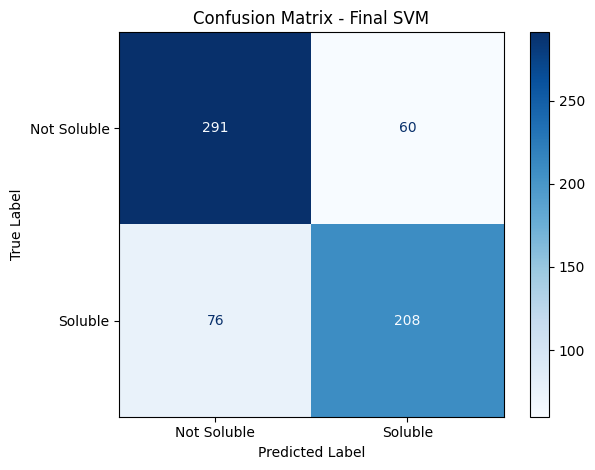

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_top,
    y_pred_best_top15,
    display_labels=["Not Soluble", "Soluble"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Final SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

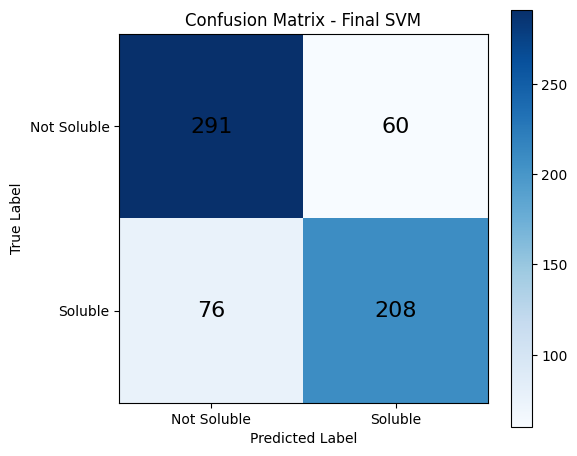

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_top, y_pred_best_top15)

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Not Soluble", "Soluble"],
    yticklabels=["Not Soluble", "Soluble"],
    xlabel="Predicted Label",
    ylabel="True Label",
    title="Confusion Matrix - Final SVM"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()
plt.show()

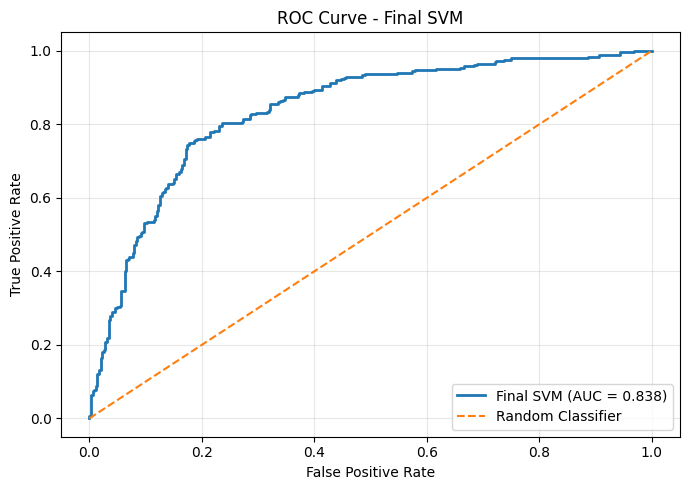

ROC-AUC: 0.8379


In [30]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability scores for the positive class
y_score = best_top15_svm.decision_function(X_test_top)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test_top, y_score)

# Calculate AUC
roc_auc = roc_auc_score(y_test_top, y_score)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Final SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")


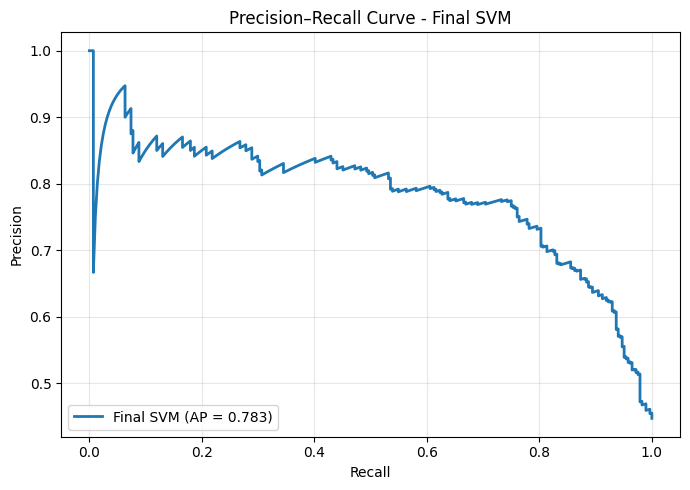

Average Precision (AP): 0.7828


In [31]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Decision scores from the final SVM
y_score = best_top15_svm.decision_function(X_test_top)

# Calculate Precision-Recall values
precision, recall, thresholds = precision_recall_curve(
    y_test_top,
    y_score
)

# Average Precision (AP)
avg_precision = average_precision_score(y_test_top, y_score)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"Final SVM (AP = {avg_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve - Final SVM")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Average Precision (AP): {avg_precision:.4f}")

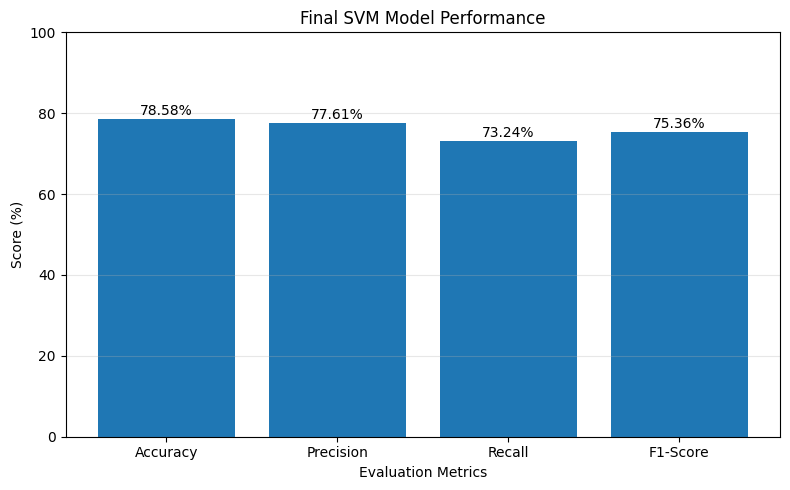

Final SVM Metrics:
Accuracy: 78.58%
Precision: 77.61%
Recall: 73.24%
F1-Score: 75.36%


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt

accuracy_final = accuracy_score(y_test_top, y_pred_best_top15)
precision_final = precision_score(y_test_top, y_pred_best_top15)
recall_final = recall_score(y_test_top, y_pred_best_top15)
f1_final = f1_score(y_test_top, y_pred_best_top15)

metrics = {
    "Accuracy": accuracy_final,
    "Precision": precision_final,
    "Recall": recall_final,
    "F1-Score": f1_final
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics.keys(),
    [value * 100 for value in metrics.values()]
)

plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metrics")
plt.title("Final SVM Model Performance")
plt.ylim(0, 100)

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value * 100 + 1,
        f"{value * 100:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Final SVM Metrics:")
for name, value in metrics.items():
    print(f"{name}: {value * 100:.2f}%")

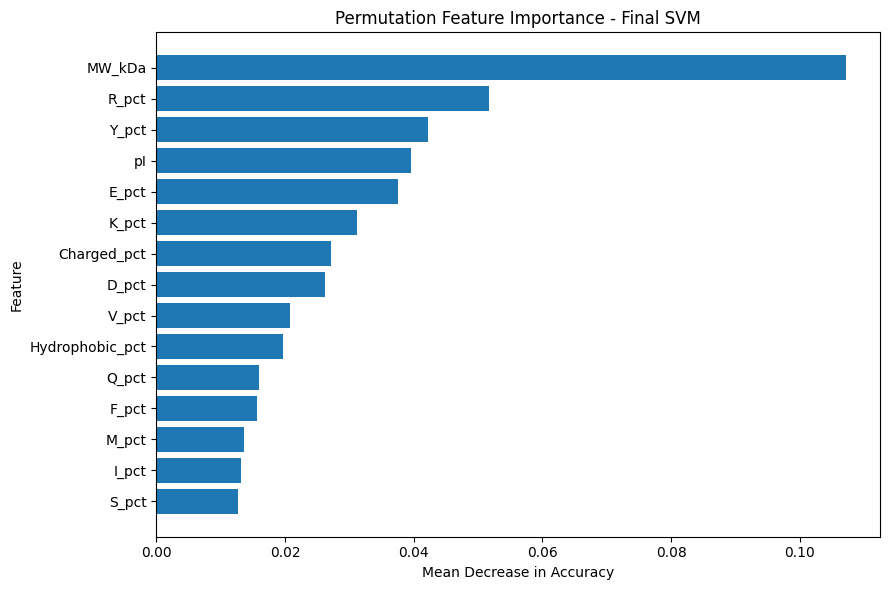


Feature Importance:
        Feature  Importance
         MW_kDa    0.107087
          R_pct    0.051654
          Y_pct    0.042205
             pI    0.039528
          E_pct    0.037480
          K_pct    0.031181
    Charged_pct    0.027087
          D_pct    0.026142
          V_pct    0.020787
Hydrophobic_pct    0.019685
          Q_pct    0.015906
          F_pct    0.015591
          M_pct    0.013701
          I_pct    0.013228
          S_pct    0.012756


In [33]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance on the test set
perm_final = permutation_importance(
    best_top15_svm,
    X_test_top,
    y_test_top,
    n_repeats=10,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

final_importance = pd.DataFrame({
    "Feature": X_test_top.columns,
    "Importance": perm_final.importances_mean
}).sort_values("Importance", ascending=True)

# Plot
plt.figure(figsize=(9, 6))

plt.barh(
    final_importance["Feature"],
    final_importance["Importance"]
)

plt.xlabel("Mean Decrease in Accuracy")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - Final SVM")

plt.tight_layout()
plt.show()

print("\nFeature Importance:")
print(
    final_importance.sort_values(
        "Importance",
        ascending=False
    ).to_string(index=False)
)

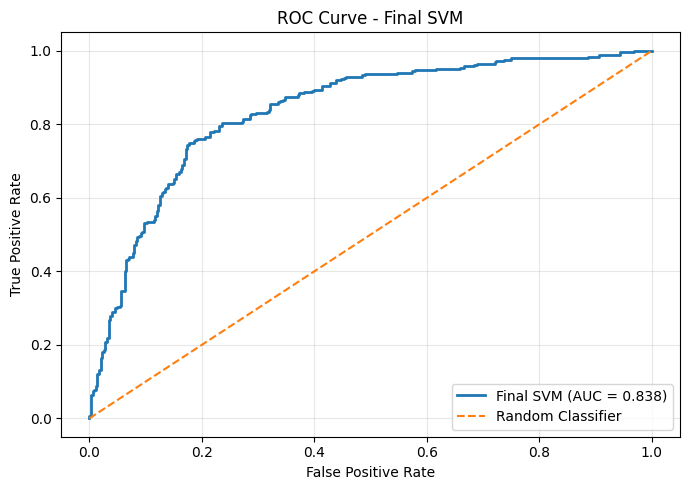

ROC-AUC: 0.8379


In [34]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Decision scores from the final SVM
y_score = best_top15_svm.decision_function(X_test_top)

# ROC values
fpr, tpr, thresholds = roc_curve(y_test_top, y_score)

# AUC
roc_auc = roc_auc_score(y_test_top, y_score)

# Plot
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Final SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")
